# Fine-tuning depth ablation — analysis

Pre-registered analysis of `experiments/ablation_finetune_depth/PROTOCOL.md` (§7–§10, deviations in §13).

* **Primary:** study-level AUROC on internal validation (691 studies, 653 patients), seed-averaged per arm; S3 vs S4 with the paired patient-cluster bootstrap (2,000 resamples, generator seed 2026) and the §9 rule (margin ±0.01). Stage 1 (3 seeds) was "inconclusive", so §10 stage 2 added seeds 101 and 202 to all arms; the 5-seed result is final.
* **Secondary (descriptive):** S2 and S1 vs S4; specificity at sensitivity ≥ 95% (06a rule), FN, FP, flagged share, AUPRC, best epoch, train/validation loss gap, minutes per epoch.
* **§13 addition:** every arm vs the frozen **Model A, C = 0.1** (`model_a@e69895841ee1`), read from a copy whose sha256 equals the value frozen in the 06a policy.
* **R0b:** S4 seed 23 rerun in the reused Colab runtime (§13).

Inputs are only the `validation_predictions.csv`, `training_log.csv` and `run_metadata.json` of each run. The official MURA `valid` split is not read. All numbers are *internal validation, development comparison* (§11).

**Execution note (20.10.2026):** this copy was executed on a local mirror of `DATA/RUNS_ARTEM` (the path printed below). Every prediction file in the mirror has the same sha256 as the Drive file (checked against `ABLATION_FINETUNE_DEPTH/inputs_bundle_20261020T224202Z.json`, written in Colab from the Drive copies). In Colab the first cell reads `DATA/RUNS_ARTEM` on Drive directly, and the results are identical.

In [1]:
import json
import os
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Input root: the team DATA/RUNS_ARTEM folder in Colab, or a local mirror with the same layout.
CANDIDATES = [
    Path("/content/drive/MyDrive/DATA/RUNS_ARTEM"),
    Path("/content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/RUNS_ARTEM"),
    Path(os.environ.get("ABLATION_LOCAL_MIRROR", "mirror")) / "RUNS_ARTEM",
]
RUNS_ROOT = next(p for p in CANDIDATES if (p / "05_MODEL_B_FINETUNE").is_dir())
STAGE_DIR = RUNS_ROOT / "05_MODEL_B_FINETUNE"
ABLATION_DIR = RUNS_ROOT / "ABLATION_FINETUNE_DEPTH"
MODEL_A_FILE = ABLATION_DIR / "model_a_C0.1_validation_predictions.csv"
MODEL_A_SHA256_06A = "03e93f6e54aa80cb15c0b8445392224b060e843c87e4d243ab59017fd4a91455"  # 06a run_20261017T105209Z
print("Reading runs from:", RUNS_ROOT)

Reading runs from: /home/claude/exp/mirror/RUNS_ARTEM


In [2]:
REGISTRY = {
    "S4": {
        "23": "run_20261017T095546Z",
        "42": "run_20261016T121029Z",
        "7": "run_20261016T123127Z",
        "101": "run_20261020T211047Z",
        "202": "run_20261020T213617Z"
    },
    "S3": {
        "23": "run_20261020T170941Z",
        "42": "run_20261020T173835Z",
        "7": "run_20261020T191814Z",
        "101": "run_20261020T205951Z",
        "202": "run_20261020T212344Z"
    },
    "S2": {
        "23": "run_20261020T192952Z",
        "42": "run_20261020T194601Z",
        "7": "run_20261020T200020Z",
        "101": "run_20261020T214625Z",
        "202": "run_20261020T215534Z"
    },
    "S1": {
        "23": "run_20261020T200935Z",
        "42": "run_20261020T202457Z",
        "7": "run_20261020T204155Z",
        "101": "run_20261020T220811Z",
        "202": "run_20261020T222524Z"
    },
    "R0b": {
        "23": "run_20261020T172538Z"
    }
}
ARMS = ["S1", "S2", "S3", "S4"]
ARM_LAYERS = {"S1": "fc", "S2": "layer4+fc", "S3": "layer3+layer4+fc", "S4": "all"}
ARM_PARAMS = {"S1": 513, "S2": 8_394_241, "S3": 10_493_953, "S4": 11_177_025}
SEEDS_STAGE1 = ["23", "42", "7"]
SEEDS_STAGE2 = ["101", "202"]          # §10: added because stage 1 was "inconclusive"
SEEDS = SEEDS_STAGE1 + SEEDS_STAGE2

## Analysis functions (also in the repository as plain code for review)

In [3]:
import hashlib
import json

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 2026
MARGIN = 0.01          # §9: smallest practically relevant AUROC difference
SENS_TARGET = 0.95     # 06a primary operating point
SPEC_MARGIN_06A = 0.02  # 06a rule: B only if spec@95 exceeds A by >= 0.02


def sha256_of(path, chunk=1 << 20):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(chunk), b""):
            digest.update(block)
    return digest.hexdigest()


def load_predictions(path):
    frame = pd.read_csv(path)
    frame["study_id"] = frame["study_id"].astype(str)
    frame["patient_id"] = frame["patient_id"].astype(str)
    return frame.sort_values("study_id").reset_index(drop=True)


def aligned_matrix(frames, reference):
    """Stack abnormal_probability of every run in the study order of `reference`."""
    ref = reference[["study_id", "patient_id", "label"]]
    columns = {}
    for name, frame in frames.items():
        merged = ref.merge(frame[["study_id", "label", "abnormal_probability"]], on="study_id",
                           how="left", validate="one_to_one", suffixes=("", "_run"))
        assert merged["abnormal_probability"].notna().all(), f"{name}: study sets differ"
        assert (merged["label"] == merged["label_run"]).all(), f"{name}: labels differ"
        columns[name] = merged["abnormal_probability"].to_numpy(dtype=float)
    return ref.reset_index(drop=True), pd.DataFrame(columns)


def operating_point(y, p, target=SENS_TARGET):
    """06a rule: highest threshold with sensitivity >= target; flag if p >= threshold."""
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    best = None
    for t in np.unique(p)[::-1]:          # from the highest candidate threshold down
        flagged = p >= t
        sens = flagged[y == 1].mean()
        if sens >= target:
            best = t
            break
    flagged = p >= best
    tp = int((flagged & (y == 1)).sum())
    fn = int((~flagged & (y == 1)).sum())
    fp = int((flagged & (y == 0)).sum())
    tn = int((~flagged & (y == 0)).sum())
    return {
        "threshold": float(best),
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "tp": tp, "fn": fn, "fp": fp, "tn": tn,
        "flagged_share": float(flagged.mean()),
    }


def per_run_table(ref, scores):
    y = ref["label"].to_numpy(dtype=int)
    rows = []
    for name in scores.columns:
        p = scores[name].to_numpy()
        op = operating_point(y, p)
        rows.append({"run": name, "auroc": roc_auc_score(y, p), "auprc": average_precision_score(y, p),
                     "spec_at_sens95": op["specificity"], "sens_at_op": op["sensitivity"],
                     "threshold95": op["threshold"], "fn": op["fn"], "fp": op["fp"],
                     "flagged_share": op["flagged_share"]})
    return pd.DataFrame(rows).set_index("run")


def _auroc_fast(y, p):
    """AUROC via the rank-sum formula (ties get average ranks); equals roc_auc_score."""
    order = np.argsort(p, kind="mergesort")
    ranks = np.empty(len(p), dtype=float)
    sorted_p = p[order]
    # average ranks for ties
    _, first, counts = np.unique(sorted_p, return_index=True, return_counts=True)
    avg = first + (counts + 1) / 2.0
    ranks[order] = np.repeat(avg, counts)
    n_pos = y.sum()
    n_neg = len(y) - n_pos
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg)


def patient_bootstrap(ref, scores, n=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED, with_spec=True):
    """Paired patient-cluster bootstrap (§8.3). Returns per-resample AUROC (and spec@95) per run."""
    patients = ref["patient_id"].to_numpy()
    unique = np.unique(patients)
    groups = [np.flatnonzero(patients == u) for u in unique]
    y_all = ref["label"].to_numpy(dtype=int)
    s_all = scores.to_numpy()
    rng = np.random.default_rng(seed)
    auc = np.empty((n, s_all.shape[1]))
    spec = np.empty((n, s_all.shape[1])) if with_spec else None
    kept = 0
    for _ in range(n):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(unique), len(unique))])
        y = y_all[idx]
        if y.min() == y.max():
            continue
        for j in range(s_all.shape[1]):
            p = s_all[idx, j]
            auc[kept, j] = _auroc_fast(y, p)
            if with_spec:
                spec[kept, j] = operating_point(y, p)["specificity"]
        kept += 1
    auc = pd.DataFrame(auc[:kept], columns=scores.columns)
    spec = pd.DataFrame(spec[:kept], columns=scores.columns) if with_spec else None
    return auc, spec


def classify(lo, hi, margin=MARGIN):
    """§9 decision rule, applied in order. 'Sx' is the arm compared with S4."""
    if lo >= -margin and hi <= margin:
        return "no practically relevant difference"
    if lo > 0:
        return "Sx better"
    if hi < 0:
        return "S4 better"
    return "inconclusive"


def arm_contrast(point_table, boot, runs_x, runs_ref, metric="auroc"):
    point = point_table.loc[runs_x, metric].mean() - point_table.loc[runs_ref, metric].mean()
    deltas = boot[runs_x].mean(axis=1) - boot[runs_ref].mean(axis=1)
    lo, hi = np.quantile(deltas, [0.025, 0.975])
    return {"delta": float(point), "ci95_lower": float(lo), "ci95_upper": float(hi),
            "resamples": int(len(deltas))}

## Inputs and integrity checks

In [4]:
rows, frames, logs = [], {}, {}
model_a = load_predictions(MODEL_A_FILE)
a_sha = sha256_of(MODEL_A_FILE)
assert a_sha == MODEL_A_SHA256_06A, "Model A file is not the frozen C = 0.1 version"
rows.append({"name": "A (C=0.1)", "run_id": "BASELINE_MODEL_A copy", "sha256": a_sha[:16]})
for arm, seeds in REGISTRY.items():
    for seed, run_id in seeds.items():
        name = f"{arm}_seed{seed}"
        run_dir = STAGE_DIR / run_id
        frames[name] = load_predictions(run_dir / "validation_predictions.csv")
        meta_file = run_dir / "run_metadata.json"
        if meta_file.exists():
            meta = json.loads(meta_file.read_text())
            expected = ARM_LAYERS.get(arm, "all")  # R0b is an S4 rerun
            layers = meta.get("trainable_layers", "all")  # pre-ablation S4 runs have no field: all layers
            assert layers == expected, f"{name}: trainable_layers {layers} != {expected}"
            assert int(meta["config"]["seed"]) == int(seed), f"{name}: seed mismatch"
            assert meta.get("official_mura_valid_read") is False
        log_file = run_dir / "training_log.csv"
        if log_file.exists():
            logs[name] = pd.read_csv(log_file)
        rows.append({"name": name, "run_id": run_id,
                     "sha256": sha256_of(run_dir / "validation_predictions.csv")[:16],
                     "metadata_checked": meta_file.exists(), "training_log": log_file.exists()})
inputs = pd.DataFrame(rows)
display(inputs)

,name,run_id,sha256,metadata_checked,training_log
0,A (C=0.1),BASELINE_MODEL_A copy,03e93f6e54aa80cb,NaN,NaN
1,S4_seed23,run_20261017T095546Z,7f4f49dfa329bf4c,True,True
2,S4_seed42,run_20261016T121029Z,b650ed04c977a2fa,True,True
3,S4_seed7,run_20261016T123127Z,049d844def78fcf5,True,True
4,S4_seed101,run_20261020T211047Z,17b4136e1af90477,True,True
5,S4_seed202,run_20261020T213617Z,bd9cb5b6f7003f37,True,True
6,S3_seed23,run_20261020T170941Z,1ccc63b634e0ea8e,True,True
7,S3_seed42,run_20261020T173835Z,c2c0bbb8e176e54b,True,True
8,S3_seed7,run_20261020T191814Z,13fdafdf57fac8d5,True,True
9,S3_seed101,run_20261020T205951Z,2e11f6e1fddf193e,True,True


In [5]:
ref, scores = aligned_matrix({"A": model_a, **frames}, model_a)
print("Studies:", len(ref), "| patients:", ref["patient_id"].nunique(),
      "| ABNORMAL:", int(ref["label"].sum()), "| NORMAL:", int((1 - ref["label"]).sum()))
per_run = per_run_table(ref, scores)
for name, log in logs.items():
    best = log.loc[log["validation_auroc_mean"].idxmax()]
    per_run.loc[name, "best_epoch"] = int(best["epoch"])
    per_run.loc[name, "epochs_run"] = int(len(log))
    per_run.loc[name, "loss_gap_at_best"] = float(best["validation_loss"] - best["train_loss"])
    per_run.loc[name, "min_per_epoch"] = float(log["minutes"].mean())
display(per_run.round(4))

Studies: 691 | patients: 653 | ABNORMAL: 269 | NORMAL: 422


,auroc,auprc,spec_at_sens95,sens_at_op,threshold95,fn,fp,flagged_share,best_epoch,epochs_run,loss_gap_at_best,min_per_epoch
run,,,,,,,,,,,,
A,0.8804,0.8515,0.3934,0.9517,0.0638,13,256,0.7410,NaN,NaN,NaN,NaN
S4_seed23,0.9020,0.8690,0.4005,0.9517,0.0306,13,253,0.7366,6.0,10.0,0.2004,0.9794
S4_seed42,0.9018,0.8731,0.3555,0.9517,0.0435,13,272,0.7641,7.0,11.0,0.2042,0.9930
S4_seed7,0.9043,0.8721,0.4692,0.9517,0.0704,13,224,0.6946,5.0,9.0,0.0455,1.0086
S4_seed101,0.9037,0.8731,0.5071,0.9517,0.0719,13,208,0.6715,6.0,10.0,0.1285,0.9961
S4_seed202,0.9020,0.8671,0.4147,0.9517,0.1703,13,247,0.7279,4.0,8.0,0.0248,1.1269
S3_seed23,0.9043,0.8795,0.4621,0.9517,0.0237,13,227,0.6990,8.0,12.0,0.3358,0.9730
S3_seed42,0.9049,0.8806,0.4242,0.9517,0.0363,13,243,0.7221,7.0,11.0,0.2872,0.9660
S3_seed7,0.9017,0.8700,0.4692,0.9517,0.1092,13,224,0.6946,2.0,6.0,-0.0184,1.0521


## Arm summary (seed mean ± SD)

In [6]:
main_runs = {arm: [f"{arm}_seed{s}" for s in SEEDS] for arm in ARMS}
summary = []
for arm in ARMS:
    t = per_run.loc[main_runs[arm]]
    summary.append({"arm": arm, "trainable_layers": ARM_LAYERS[arm], "trainable_params": ARM_PARAMS[arm],
                     "auroc_mean": t["auroc"].mean(), "auroc_sd": t["auroc"].std(ddof=1),
                     "auprc_mean": t["auprc"].mean(),
                     "spec95_mean": t["spec_at_sens95"].mean(), "spec95_sd": t["spec_at_sens95"].std(ddof=1),
                     "fp_mean": t["fp"].mean(), "fn_mean": t["fn"].mean(),
                     "best_epoch_mean": t.get("best_epoch", pd.Series(dtype=float)).mean(),
                     "loss_gap_mean": t.get("loss_gap_at_best", pd.Series(dtype=float)).mean(),
                     "min_per_epoch_mean": t.get("min_per_epoch", pd.Series(dtype=float)).mean()})
summary = pd.DataFrame(summary).set_index("arm")
summary.loc["A (C=0.1)", ["auroc_mean", "auprc_mean", "spec95_mean", "fp_mean", "fn_mean"]] = (
    per_run.loc["A", ["auroc", "auprc", "spec_at_sens95", "fp", "fn"]].to_numpy())
display(summary.round(4))

,trainable_layers,trainable_params,auroc_mean,auroc_sd,auprc_mean,spec95_mean,spec95_sd,fp_mean,fn_mean,best_epoch_mean,loss_gap_mean,min_per_epoch_mean
arm,,,,,,,,,,,,
S1,fc,513.0,0.8611,0.0030,0.8172,0.4242,0.0224,243.0,13.0,15.0,-0.0138,0.9778
S2,layer4+fc,8394241.0,0.9012,0.0031,0.8737,0.4545,0.0293,230.2,13.0,3.6,0.0617,1.0215
S3,layer3+layer4+fc,10493953.0,0.9039,0.0028,0.8787,0.4431,0.0213,235.0,13.0,5.4,0.1843,1.0179
S4,all,11177025.0,0.9028,0.0012,0.8709,0.4294,0.0595,240.8,13.0,5.6,0.1207,1.0208
A (C=0.1),NaN,NaN,0.8804,NaN,0.8515,0.3934,NaN,256.0,13.0,NaN,NaN,NaN


## Paired patient-cluster bootstrap (§8.3)

In [7]:
boot_auc, boot_spec = patient_bootstrap(ref, scores)
print("Valid resamples:", len(boot_auc))

Valid resamples: 2000


## Primary comparison S3 vs S4 and the §9 decision

Stage 1 uses seeds 23, 42, 7. If it is "inconclusive", §10 adds seeds 101 and 202 to all arms and the analysis is repeated **once** with 5 seeds; that repeat is the final decision.

In [8]:
stage1 = arm_contrast(per_run, boot_auc, [f"S3_seed{s}" for s in SEEDS_STAGE1], [f"S4_seed{s}" for s in SEEDS_STAGE1])
stage1["decision"] = classify(stage1["ci95_lower"], stage1["ci95_upper"]).replace("Sx", "S3")
primary = arm_contrast(per_run, boot_auc, main_runs["S3"], main_runs["S4"])
primary["decision"] = classify(primary["ci95_lower"], primary["ci95_upper"]).replace("Sx", "S3")
display(pd.DataFrame([{"stage": "1 (3 seeds)", **stage1}, {"stage": "2 (5 seeds, final)", **primary}]).set_index("stage").round(4))
seed_matched = {s: per_run.loc[f"S3_seed{s}", "auroc"] - per_run.loc[f"S4_seed{s}", "auroc"] for s in SEEDS}
print("Seed-matched AUROC differences S3 - S4:", {k: round(v, 4) for k, v in seed_matched.items()})
print("Seed SD of AUROC within arm:", summary["auroc_sd"].dropna().round(4).to_dict())

,delta,ci95_lower,ci95_upper,resamples,decision
stage,,,,,
1 (3 seeds),0.0009,-0.0091,0.0117,2000,inconclusive
"2 (5 seeds, final)",0.0011,-0.0072,0.0089,2000,no practically relevant difference


Seed-matched AUROC differences S3 - S4: {'23': np.float64(0.0022), '42': np.float64(0.0031), '7': np.float64(-0.0027), '101': np.float64(-0.0029), '202': np.float64(0.0058)}
Seed SD of AUROC within arm: {'S1': 0.003, 'S2': 0.0031, 'S3': 0.0028, 'S4': 0.0012}


## Secondary: S2 and S1 vs S4 (descriptive)

In [9]:
secondary = []
for arm in ["S2", "S1"]:
    c = arm_contrast(per_run, boot_auc, main_runs[arm], main_runs["S4"])
    c.update({"contrast": f"{arm} - S4", "rule_9_applied_descriptively": classify(c["ci95_lower"], c["ci95_upper"]).replace("Sx", arm)})
    secondary.append(c)
secondary = pd.DataFrame(secondary).set_index("contrast")
display(secondary.round(4))

,delta,ci95_lower,ci95_upper,resamples,rule_9_applied_descriptively
contrast,,,,,
S2 - S4,-0.0016,-0.0126,0.0098,2000,inconclusive
S1 - S4,-0.0417,-0.0643,-0.0183,2000,S4 better


## §13 addition: every arm vs frozen Model A (C = 0.1)

In [10]:
vs_a = []
for arm in ARMS:
    auc = arm_contrast(per_run, boot_auc, main_runs[arm], ["A"])
    spec = arm_contrast(per_run, boot_spec, main_runs[arm], ["A"], metric="spec_at_sens95")
    vs_a.append({"arm": arm,
                 "delta_auroc": auc["delta"], "auroc_ci95": f"[{auc['ci95_lower']:+.4f}, {auc['ci95_upper']:+.4f}]",
                 "delta_spec95": spec["delta"], "spec95_ci95": f"[{spec['ci95_lower']:+.4f}, {spec['ci95_upper']:+.4f}]",
                 "seeds_with_spec_gain_ge_0.02": int((per_run.loc[main_runs[arm], "spec_at_sens95"]
                                                      - per_run.loc["A", "spec_at_sens95"] >= SPEC_MARGIN_06A).sum()),
                 "mean_spec_gain_ge_0.02": bool(spec["delta"] >= SPEC_MARGIN_06A)})
vs_a = pd.DataFrame(vs_a).set_index("arm")
display(vs_a.round(4))
print("The specificity CI re-derives the 95%-sensitivity threshold inside every resample (descriptive).")

,delta_auroc,auroc_ci95,delta_spec95,spec95_ci95,seeds_with_spec_gain_ge_0.02,mean_spec_gain_ge_0.02
arm,,,,,,
S1,-0.0193,"[-0.0365, -0.0020]",0.0308,"[-0.0880, +0.1149]",3,True
S2,0.0208,"[+0.0046, +0.0375]",0.0611,"[-0.0333, +0.1668]",5,True
S3,0.0235,"[+0.0064, +0.0413]",0.0498,"[-0.0784, +0.1699]",5,True
S4,0.0224,"[+0.0029, +0.0421]",0.0360,"[-0.0883, +0.1801]",3,True


The specificity CI re-derives the 95%-sensitivity threshold inside every resample (descriptive).


## R0b: reproducibility in the reused Colab runtime (§13)

In [11]:
if "R0b" in REGISTRY:
    r0b = per_run.loc["R0b_seed23", "auroc"]
    ref_auc = per_run.loc["S4_seed23", "auroc"]
    max_abs = float(np.max(np.abs(frames["R0b_seed23"]["abnormal_probability"].to_numpy()
                                  - frames["S4_seed23"]["abnormal_probability"].to_numpy())))
    verdict = "PASS" if abs(r0b - ref_auc) <= 0.005 else "FAIL"
    print(f"R0b AUROC {r0b:.16f} vs {ref_auc:.16f} | delta {r0b - ref_auc:+.2e} | max |dp| {max_abs:.2e} -> {verdict}")

R0b AUROC 0.9020419669127363 vs 0.9020419669127363 | delta +0.00e+00 | max |dp| 0.00e+00 -> PASS


## Figure: AUROC by number of trainable parameters

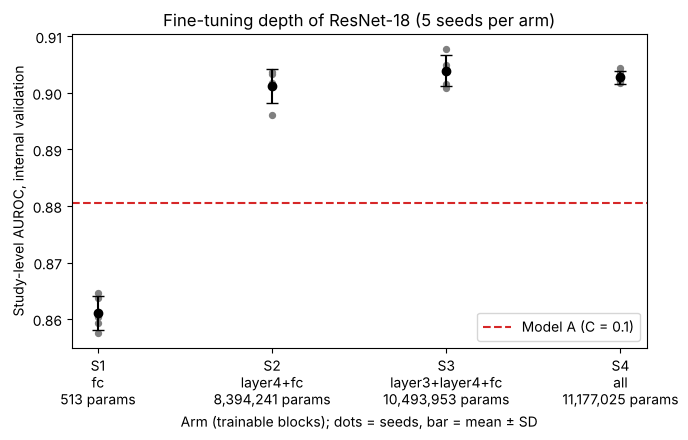

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for x, arm in enumerate(ARMS):
    t = per_run.loc[main_runs[arm], "auroc"]
    ax.scatter([x] * len(t), t, color="gray", s=18, zorder=2)
    ax.errorbar(x, t.mean(), yerr=t.std(ddof=1), fmt="o", color="black", capsize=4, zorder=3)
ax.axhline(per_run.loc["A", "auroc"], linestyle="--", color="tab:red", label="Model A (C = 0.1)")
ax.set_xticks(range(len(ARMS)), [f"{a}\n{ARM_LAYERS[a]}\n{ARM_PARAMS[a]:,} params" for a in ARMS])
ax.set_xlabel("Arm (trainable blocks); dots = seeds, bar = mean ± SD")
ax.set_ylabel("Study-level AUROC, internal validation")
ax.set_title(f"Fine-tuning depth of ResNet-18 ({len(SEEDS)} seeds per arm)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Save results (new folder; nothing existing is changed)

In [13]:
out_dir = ABLATION_DIR / datetime.now(timezone.utc).strftime("analysis_%Y%m%dT%H%M%SZ")
out_dir.mkdir(parents=True, exist_ok=False)
per_run.to_csv(out_dir / "per_run_metrics.csv")
summary.to_csv(out_dir / "arm_summary.csv")
secondary.to_csv(out_dir / "secondary_vs_s4.csv")
vs_a.to_csv(out_dir / "arms_vs_model_a_c01.csv")
fig.savefig(out_dir / "auroc_by_trainable_params.png", dpi=160, bbox_inches="tight")
(out_dir / "primary_s3_vs_s4.json").write_text(json.dumps({"stage1": stage1, "final_stage2": primary, "seed_matched": seed_matched,
    "bootstrap": {"resamples": BOOTSTRAP_RESAMPLES, "seed": BOOTSTRAP_SEED, "margin": MARGIN},
    "inputs": inputs.to_dict(orient="records")}, indent=2, default=float), encoding="utf-8")
print("Saved to:", out_dir)

Saved to: /home/claude/exp/mirror/RUNS_ARTEM/ABLATION_FINETUNE_DEPTH/analysis_20261020T225136Z
